In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import scipy.linalg as la
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

In [3]:
# -- Definition of constants --
b = 4.0
V0 = 50.0
Nmax = 50
Emax = 50.0

In [4]:
# -- Definition of functions for Matrix Method --

def matrix_method(V, Nmax, b, dim='1D', m_quant=0):
    """_summary_

    Args:
        V (_type_): _description_
        Nmax (_type_): _description_
        b (_type_): _description_
        dim (str, optional): _description_. Defaults to '1D'.
        m_quant (int, optional): _description_. Defaults to 0.

    Returns:
        _type_: _description_
    """
    def basis_func(n, x):
        return np.sqrt(2.0/b) * np.sin(n * np.pi * x / b)
    
    H = np.zeros((Nmax, Nmax))
    
    # First the elements in the diagonal
    E_0 = [(n**2 * np.pi**2) / (2.0 * b**2) for n in range(1, Nmax + 1)]
    
    # Populate the diagonal elements in the matrix
    for i in range(Nmax):
        H[i,i] = E_0[i]
        
    def Veff(x):
        if dim =='1D':
            return V(x)
        elif dim =='2D_radial':
            if x <= 1e-12:
                return V(x)
            centrifugal_term = (m_quant**2 - 0.25) / (2.0 * x**2)
            return V(x) + centrifugal_term
    
    # Now we will compute the other matrix elements by using nested loops and
    # numerical integration. 
    for n in range(Nmax):
        n_index = n + 1
        for m in range(Nmax): 
            m_index = m + 1
            integrand = lambda x: basis_func(n_index, x) * Veff(x) * basis_func(m_index, x)
            V_nm, _ = quad(integrand, 0.0, b, limit=100)
            H[n, m] += V_nm
            
    energies, vectors = la.eigh(H)
    return H, energies, vectors

def reconstruct_wavefunction(vectors, energies, b, Nmax, Emax):
    """
        _summary_
    Args:
        vectors (_type_): _description_
        energies (_type_): _description_
        b (_type_): _description_
        Nmax (_type_): _description_
        Emax (_type_): _description_

    Returns:
        _type_: _description_
    """

    bound_state_indices = np.where(energies <= Emax)[0]
    bound_state_vectors = vectors[:, bound_state_indices]
    bound_state_energies = energies[bound_state_indices]
        
    x_grid = np.linspace(0, b, 1000)
    all_n_indices = np.arange(1, Nmax + 1)
    
    Phi = np.sqrt(2.0 / b) * np.sin(np.outer(x_grid, all_n_indices * np.pi / b))
    
    print(np.shape(Phi)) # This returns a 1000xNmax matrix with the basis functions evaluated at 1000 points in x.
    print(np.shape(bound_state_vectors)) # This returns a NmaxxNmax matrix withÇ
    
    Psi = Phi @ bound_state_vectors
    probability_density = np.abs(Psi)**2
    
    return x_grid, Psi, probability_density, bound_state_energies # This returns a 2D matrix with Nmax amount of functions for different energies eigenvalues for a 1000 values of x.


In [5]:
def plot_bound_states_grid(x_grid, Psi, prob_density, bound_energies, Emax, b=4.0, ncols=2):
    """
    Plots a grid of subplots for all bound states, displaying both 
    the wavefunction Psi(x) and probability density |Psi(x)|^2.
    """
    num_states = len(bound_energies)
    nrows = (num_states + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows), sharex=True)
    
    # Flatten axes for iteration (handles single-row edge case)
    axes = np.atleast_1d(axes).flatten()
    
    for k in range(num_states):
        ax = axes[k]
        
        # 1. Left Y-axis: Wavefunction Psi(x)
        color_psi = 'tab:blue'
        ax.set_ylabel('Psi(x)', color=color_psi, fontsize=11)
        ax.plot(x_grid, Psi[:, k], color=color_psi, linewidth=2, label='Psi(x)')
        ax.tick_params(axis='y', labelcolor=color_psi)
        ax.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)
        
        # 2. Right Y-axis: Probability Density |Psi(x)|^2
        ax2 = ax.twinx()
        color_prob = 'tab:red'
        ax2.set_ylabel('|Psi(x)|^2', color=color_prob, fontsize=11)
        ax2.plot(x_grid, prob_density[:, k], color=color_prob, linewidth=1.8, label='|Psi(x)|^2')
        ax2.fill_between(x_grid, 0, prob_density[:, k], color=color_prob, alpha=0.15)
        ax2.tick_params(axis='y', labelcolor=color_prob)
        
        # Subplot Title & Limits
        ax.set_title(f'Bound State {k+1}: E = {bound_energies[k]:.3f}', fontsize=12, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.set_xlim(0, b)

    # Add x-axis label to the bottom row
    for ax in axes[-ncols:]:
        ax.set_xlabel('Position x', fontsize=11)

    # Remove unused empty subplots if num_states is odd
    for k in range(num_states, len(axes)):
        fig.delaxes(axes[k])

    plt.suptitle(f"Bound State Wavefunctions and Probability Densities (E <= {Emax})", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

In [6]:
def shooting_method(V, b, Emax=50.0, dim='1D', m_quant=0, n_scan=300, symmetric=True):
    """
    Generalized Shooting Method for finding bound state energies on [0, b].
    Mirrors the interface of matrix_method().

    Args:
        V (callable): Potential function V(x) defined on [0, b].
        b (float): Integration domain width [0, b] (centered at b/2 for symmetric 1D potentials).
        Emax (float, optional): Maximum energy for bound states (V0). Defaults to 50.0.
        dim (str, optional): '1D' or '2D_radial'. Defaults to '1D'.
        m_quant (int, optional): Angular momentum quantum number for '2D_radial'. Defaults to 0.
        n_scan (int, optional): Number of energy grid points to bracket roots. Defaults to 300.
        symmetric (bool, optional): If True (and dim=='1D'), exploits parity symmetry about x = b/2
                                    by integrating from b/2 to b. Defaults to True.

    Returns:
        bound_energies (np.ndarray): Array of bound state energy eigenvalues.
        state_parities (list): List of parity labels ('even', 'odd', or 'full') for reconstruction.
    """
    def Veff(x):
        if dim == '1D':
            return V(x)
        elif dim == '2D_radial':
            r = max(x, 1e-9)
            return V(r) + (m_quant**2 - 0.25) / (2.0 * r**2)

    def ode_rhs(x, y, E):
        # y[0] = Psi(x), y[1] = Psi'(x)
        return [y[1], -2.0 * (E - Veff(x)) * y[0]]

    E_grid = np.linspace(0.1, Emax - 1e-3, n_scan)
    found_states = []

    if dim == '1D' and symmetric:
        # Integrate from center (x = b/2) to right boundary (x = b)
        x_center = b / 2.0
        for parity in ['even', 'odd']:
            y0 = [1.0, 0.0] if parity == 'even' else [0.0, 1.0]
            
            def shoot_bc(E):
                sol = solve_ivp(ode_rhs, (x_center, b), y0, args=(E,), max_step=0.005, rtol=1e-8, atol=1e-8)
                return sol.y[0, -1]

            vals = [shoot_bc(E) for E in E_grid]
            for i in range(len(E_grid) - 1):
                if vals[i] * vals[i + 1] < 0:
                    res = root_scalar(shoot_bc, bracket=[E_grid[i], E_grid[i + 1]], method='brentq')
                    if res.converged:
                        found_states.append((res.root, parity))
    else:
        # Full-domain shooting from x_start to b (for asymmetric 1D or 2D_radial)
        x_start = 1e-6 if dim == '2D_radial' else 0.0
        
        def shoot_bc_full(E):
            if dim == '2D_radial':
                # Asymptotic behavior near r -> 0: u(r) ~ r^(|m| + 1/2)
                p = abs(m_quant) + 0.5
                y0 = [x_start**p, p * (x_start**(p - 1.0))]
            else:
                y0 = [0.0, 1.0]
            sol = solve_ivp(ode_rhs, (x_start, b), y0, args=(E,), max_step=0.005, rtol=1e-8, atol=1e-8)
            return sol.y[0, -1]

        vals = [shoot_bc_full(E) for E in E_grid]
        for i in range(len(E_grid) - 1):
            if vals[i] * vals[i + 1] < 0:
                res = root_scalar(shoot_bc_full, bracket=[E_grid[i], E_grid[i + 1]], method='brentq')
                if res.converged:
                    found_states.append((res.root, 'full'))

    # Sort states by ascending energy
    found_states.sort(key=lambda item: item[0])
    bound_energies = np.array([item[0] for item in found_states])
    state_parities = [item[1] for item in found_states]

    return bound_energies, state_parities

In [7]:
def reconstruct_shooting_wavefunction(V, bound_energies, state_parities, b, dim='1D', m_quant=0, num_pts=1000):
    """
    Reconstructs and normalizes wavefunctions on [0, b] from shooting_method results.
    Matches the return signature of reconstruct_wavefunction().

    Returns:
        x_grid (np.ndarray): 1D array of x values on [0, b].
        Psi (np.ndarray): 2D array (num_pts x num_states) of normalized wavefunctions.
        probability_density (np.ndarray): 2D array of |Psi(x)|^2.
        bound_energies (np.ndarray): 1D array of bound state energies.
    """
    def Veff(x):
        if dim == '1D':
            return V(x)
        elif dim == '2D_radial':
            r = max(x, 1e-9)
            return V(r) + (m_quant**2 - 0.25) / (2.0 * r**2)

    def ode_rhs(x, y, E):
        return [y[1], -2.0 * (E - Veff(x)) * y[0]]

    psi_list = []

    if dim == '1D' and len(state_parities) > 0 and state_parities[0] in ['even', 'odd']:
        half_pts = num_pts // 2 + 1
        x_right = np.linspace(b / 2.0, b, half_pts)
        x_left = b - x_right[::-1][:-1]
        x_grid = np.concatenate([x_left, x_right])

        for E, parity in zip(bound_energies, state_parities):
            y0 = [1.0, 0.0] if parity == 'even' else [0.0, 1.0]
            sol = solve_ivp(ode_rhs, (b / 2.0, b), y0, args=(E,), t_eval=x_right, max_step=0.005, rtol=1e-8, atol=1e-8)
            psi_r = sol.y[0]
            psi_l = psi_r[::-1][:-1] if parity == 'even' else -psi_r[::-1][:-1]
            psi = np.concatenate([psi_l, psi_r])

            # Normalize wavefunction on [0, b]
            norm = np.sqrt(np.trapezoid(psi**2, x_grid))
            psi_list.append(psi / norm)
    else:
        x_start = 1e-6 if dim == '2D_radial' else 0.0
        x_grid = np.linspace(x_start, b, num_pts)

        for E in bound_energies:
            if dim == '2D_radial':
                p = abs(m_quant) + 0.5
                y0 = [x_start**p, p * (x_start**(p - 1.0))]
            else:
                y0 = [0.0, 1.0]
            sol = solve_ivp(ode_rhs, (x_start, b), y0, args=(E,), t_eval=x_grid, max_step=0.005, rtol=1e-8, atol=1e-8)
            psi = sol.y[0]

            # Normalize wavefunction on [0, b]
            norm = np.sqrt(np.trapezoid(psi**2, x_grid))
            psi_list.append(psi / norm)

    Psi = np.column_stack(psi_list) if psi_list else np.empty((len(x_grid), 0))
    probability_density = np.abs(Psi)**2

    return x_grid, Psi, probability_density, bound_energies

In [8]:
def single_well_potential(x):
    

_IncompleteInputError: incomplete input (2163306499.py, line 2)

In [ ]:
matrix_method(V, Nmax, b, dim='1D', m_quant=0)

--- Single Well Bound States (SHOOTING METHOD, b = 4.0 / x_max = 2.0) ---
State 1 (even): E = 3.41357 | P(|x|>a/2) = 0.12053 | P(|x|>a) = 0.000015
State 2 (odd ): E = 13.47571 | P(|x|>a/2) = 0.47322 | P(|x|>a) = 0.000174
State 3 (even): E = 29.45230 | P(|x|>a/2) = 1.01525 | P(|x|>a) = 0.003108
State 4 (odd ): E = 48.15489 | P(|x|>a/2) = 1.43358 | P(|x|>a) = 0.329436


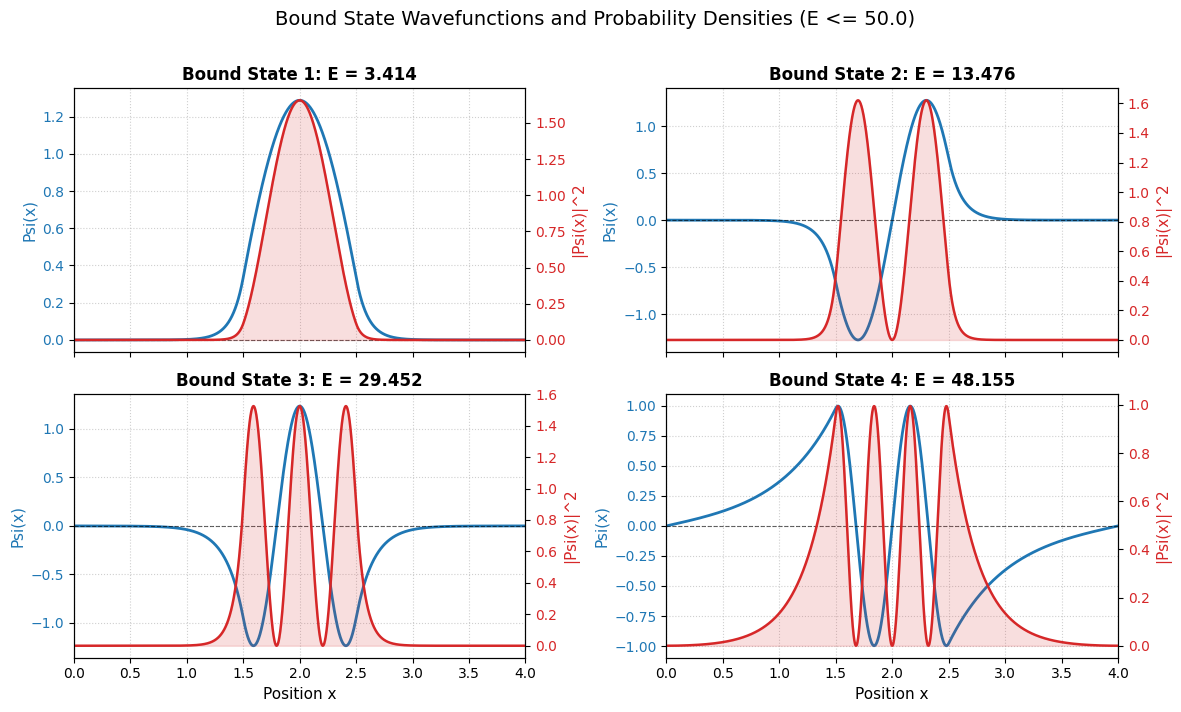


=== Shooting Precision 1: Varying Integration Range b (where x_max = b/2) ===
b = 2.0 (x_max = 1.00) | Energies = [ 3.41371 13.47716 29.4713  48.91658] | P(|x|>a/2) = [0.12263 0.48024 1.02476 1.51333]
b = 2.5 (x_max = 1.25) | Energies = [ 3.41357 13.47574 29.45308 48.38468] | P(|x|>a/2) = [0.12213 0.47867 1.02366 1.47689]
b = 3.0 (x_max = 1.50) | Energies = [ 3.41357 13.47572 29.45234 48.22726] | P(|x|>a/2) = [0.12266 0.48051 1.02657 1.45553]
b = 4.0 (x_max = 2.00) | Energies = [ 3.41357 13.47571 29.4523  48.15489] | P(|x|>a/2) = [0.12053 0.47322 1.01525 1.43358]
b = 6.0 (x_max = 3.00) | Energies = [ 3.41357 13.47571 29.4523  48.1437 ] | P(|x|>a/2) = [0.12266 0.48052 1.02659 1.43193]

=== Shooting Precision 2: Varying Normalization Requirement (at fixed b = 4.0) ===


TypeError: reconstruct_shooting_wavefunction() got an unexpected keyword argument 'norm_cutoff'

In [ ]:
#  Single Finite-Depth Well (SHOOTING METHOD) & Precision Analysis
a = 1.0
V0 = 50.0
b = 4.0      # Integration range [0, b] centered at b/2 -> x in [-2.0, +2.0]
Emax = 50.0

def V_single_well(x, a=a, b=b, V0=V0):
    """Finite square well of width a centered at b/2."""
    return 0.0 if abs(x - b / 2.0) <= (a / 2.0) else V0

# 1. Bullet 1: Find energies and wave functions for all bound states (E < V0) using shooting method
bound_E_sh, parities_sh = shooting_method(V_single_well, b=b, Emax=Emax, dim='1D', symmetric=True)
x_sh, Psi_sh, prob_sh, bound_E_sh = reconstruct_shooting_wavefunction(
    V_single_well, bound_E_sh, parities_sh, b=b, dim='1D', num_pts=2000
)

# 2. Bullet 2: Find probability of a particle to be outside the well for all bound states
center = b / 2.0
mask_edge = np.abs(x_sh - center) > (a / 2.0)  # Strictly outside the well (|x| > a/2 = 0.5)
mask_a    = np.abs(x_sh - center) > a          # As printed in text (|x| > a = 1.0)

print("--- Single Well Bound States (SHOOTING METHOD, b = 4.0 / x_max = 2.0) ---")
for k, E in enumerate(bound_E_sh):
    p_out_edge = np.trapezoid(prob_sh[mask_edge, k], x_sh[mask_edge])
    p_out_a    = np.trapezoid(prob_sh[mask_a, k], x_sh[mask_a])
    print(f"State {k+1} ({parities_sh[k]:4s}): E = {E:.5f} | P(|x|>a/2) = {p_out_edge:.5f} | P(|x|>a) = {p_out_a:.6f}")

# Plot the bound states from the Shooting Method
plot_bound_states_grid(x_sh, Psi_sh, prob_sh, bound_E_sh, Emax, b=b)



In [ ]:
# Single Finite-Depth Well (MATRIX METHOD) & Precision Analysis 
Nmax = 50

# 1. Bullet 4: Solve the same problem using the matrix method
H_sw, energies_sw, vectors_sw = matrix_method(V_single_well, Nmax, b, dim='1D')
x_sw, Psi_sw, prob_sw, bound_E_sw = reconstruct_wavefunction(vectors_sw, energies_sw, b, Nmax, Emax)

center = b / 2.0
mask_edge_sw = np.abs(x_sw - center) > (a / 2.0)
mask_a_sw    = np.abs(x_sw - center) > a

print("\n--- Single Well Bound States (MATRIX METHOD, Nmax = 50, b = 4.0) ---")
for k, E in enumerate(bound_E_sw):
    p_out_edge = np.trapezoid(prob_sw[mask_edge_sw, k], x_sw[mask_edge_sw])
    p_out_a    = np.trapezoid(prob_sw[mask_a_sw, k], x_sw[mask_a_sw])
    diff_E     = abs(E - bound_E_sh[k])
    print(f"State {k+1}: E_mat = {E:.5f} (|E_mat - E_shoot| = {diff_E:.5f}) | P(|x|>a/2) = {p_out_edge:.5f} | P(|x|>a) = {p_out_a:.6f}")

# Plot the bound states from the Matrix Method
plot_bound_states_grid(x_sw, Psi_sw, prob_sw, bound_E_sw, Emax, b=b)

